# DataFrames de Pandas, Arquitectura Medallón y limpieza de datos

En la clase anterior trabajamos con **Series** (una sola columna de datos). Hoy damos el salto a la estructura que realmente se usa en el día a día del análisis de datos: el **DataFrame**.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import os

print("pandas:", pd.__version__)

pandas: 2.2.3


---
# Parte 1. ¿Qué es un DataFrame?

Un **DataFrame** es una **tabla de dos dimensiones**: filas y columnas, igual que una hoja de Excel o una tabla de una base de datos.

- Cada **fila** es una **observación** (un producto, un estudiante, un pingüino...).
- Cada **columna** es una **variable** (el precio, la edad, el peso...).
- Cada **columna es una `Series`**. Un DataFrame es, en el fondo, un conjunto de Series que comparten el mismo índice.

Empecemos con un ejemplo sencillo: el inventario de una pequeña tienda.

In [2]:
tienda = pd.DataFrame({
    "producto":  ["Cuaderno", "Lápiz", "Borrador", "Regla", "Mochila"],
    "precio":    [2.50, 0.50, 0.75, 1.20, 18.00],
    "cantidad":  [30, 100, 45, 20, 5],
    "categoria": ["Papelería", "Papelería", "Papelería", "Útiles", "Accesorios"],
})
tienda

,producto,precio,cantidad,categoria
0,Cuaderno,2.50,30,Papelería
1,Lápiz,0.50,100,Papelería
2,Borrador,0.75,45,Papelería
3,Regla,1.20,20,Útiles
4,Mochila,18.00,5,Accesorios


El diccionario que usamos tiene una **clave por cada columna** y una **lista con los valores** de esa columna.

### Anatomía de un DataFrame

In [3]:
tienda.shape        # (filas, columnas)

(5, 4)

In [4]:
tienda.columns      # nombres de las columnas

Index(['producto', 'precio', 'cantidad', 'categoria'], dtype='object')

In [5]:
tienda.index        # etiquetas de las filas

RangeIndex(start=0, stop=5, step=1)

Pandas le puso al índice los números `0, 1, 2, 3, 4` automáticamente. Más adelante veremos cómo usar otra columna como índice.

Ahora comprobemos que **cada columna es una Series**:

In [6]:
type(tienda["precio"])

pandas.core.series.Series

In [7]:
tienda.dtypes       # tipo de dato de cada columna

,0
producto,object
precio,float64
cantidad,int64
categoria,object


### Los ejes: `axis=0` y `axis=1`

Como ahora hay dos dimensiones, muchas operaciones necesitan saber **en qué dirección** trabajar:

- `axis=0`: la operación **recorre las filas hacia abajo**, así que el resultado es **uno por cada columna**.
- `axis=1`: la operación **recorre las columnas hacia el lado**, así que el resultado es **uno por cada fila**.

Lo vemos con un ejemplo de notas de tres estudiantes:

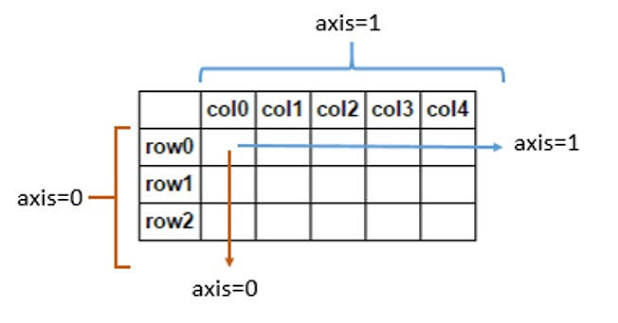

In [8]:
notas = pd.DataFrame(
    {"parcial1": [80, 70, 90], "parcial2": [85, 60, 95]}, index=["Ana", "Luis", "María"],
)
notas

,parcial1,parcial2
Ana,80,85
Luis,70,60
María,90,95


In [9]:
notas.mean(axis=0)   # promedio de cada parcial entre todos los estudiantes (uno por columna)

,0
parcial1,80.0
parcial2,80.0


In [10]:
notas.mean(axis=1)   # promedio de cada estudiante (uno por fila)

,0
Ana,82.5
Luis,65.0
María,92.5


### Otras formas de crear un DataFrame

Según cómo vengan tus datos, hay varias opciones.

In [11]:
# Desde una lista de listas: cada lista interna es una FILA
filas = [["Ana", 20], ["Luis", 22], ["María", 21]]
pd.DataFrame(filas, columns=["nombre", "edad"])

,nombre,edad
0,Ana,20
1,Luis,22
2,María,21


In [12]:
# Con from_dict: parecido a pd.DataFrame(), pero permite elegir la orientación
datos = {"nombre": ["Ana", "Luis", "María"], "edad": [20, 22, 21]}
pd.DataFrame.from_dict(datos)

,nombre,edad
0,Ana,20
1,Luis,22
2,María,21


In [13]:
# Con orient="index", cada clave del diccionario pasa a ser una FILA
por_fila = {"Ana": {"edad": 20, "ciudad": "Panamá"},
            "Luis": {"edad": 22, "ciudad": "Guatemala"}}
pd.DataFrame.from_dict(por_fila, orient="index")

,edad,ciudad
Ana,20,Panamá
Luis,22,Guatemala


### Seleccionar columnas y filas

Esto ya lo conocen de las Series, pero ahora con dos dimensiones.

In [14]:
tienda["precio"]                       # una columna  -> Series

,precio
0,2.50
1,0.50
2,0.75
3,1.20
4,18.00


In [15]:
tienda[["producto", "precio"]]         # varias columnas -> DataFrame (nota los corchetes dobles)

,producto,precio
0,Cuaderno,2.50
1,Lápiz,0.50
2,Borrador,0.75
3,Regla,1.20
4,Mochila,18.00


También se puede escribir `tienda.precio` (notación de punto). Funciona, pero falla si el nombre de la columna tiene espacios o coincide con un método de Pandas, así que **recomendamos los corchetes**.

### Filtrar filas con una condición

In [16]:
tienda[tienda["precio"] > 2]

,producto,precio,cantidad,categoria
0,Cuaderno,2.5,30,Papelería
4,Mochila,18.0,5,Accesorios


In [17]:
# Varias condiciones: & (y), | (o), cada una entre paréntesis
tienda[(tienda["categoria"] == "Papelería") & (tienda["cantidad"] > 40)]

,producto,precio,cantidad,categoria
1,Lápiz,0.50,100,Papelería
2,Borrador,0.75,45,Papelería


### `loc` e `iloc` con filas y columnas

- `.loc[fila, columna]` usa **etiquetas**.
- `.iloc[fila, columna]` usa **posiciones**.

In [18]:
tienda.loc[0, "producto"]

'Cuaderno'

In [19]:
tienda.iloc[0:3, 0:2]      # filas 0 a 2 y columnas 0 a 1 (el final NO se incluye)

,producto,precio
0,Cuaderno,2.50
1,Lápiz,0.50
2,Borrador,0.75


### Manipular: crear, eliminar, renombrar y ordenar

In [20]:
# Crear una columna nueva a partir de otras
tienda["total"] = tienda["precio"] * tienda["cantidad"]

tienda

,producto,precio,cantidad,categoria,total
0,Cuaderno,2.50,30,Papelería,75.00
1,Lápiz,0.50,100,Papelería,50.00
2,Borrador,0.75,45,Papelería,33.75
3,Regla,1.20,20,Útiles,24.00
4,Mochila,18.00,5,Accesorios,90.00


**Eliminar con `drop()`** (aquí sí importa el eje):

- `axis=0` elimina **filas** (por defecto).
- `axis=1` elimina **columnas**.

In [21]:
tienda.drop(columns=["categoria"])      # equivale a drop("categoria", axis=1)

,producto,precio,cantidad,total
0,Cuaderno,2.50,30,75.00
1,Lápiz,0.50,100,50.00
2,Borrador,0.75,45,33.75
3,Regla,1.20,20,24.00
4,Mochila,18.00,5,90.00


In [22]:
tienda.drop("categoria", axis=1)

,producto,precio,cantidad,total
0,Cuaderno,2.50,30,75.00
1,Lápiz,0.50,100,50.00
2,Borrador,0.75,45,33.75
3,Regla,1.20,20,24.00
4,Mochila,18.00,5,90.00


In [23]:
tienda.drop(2, axis=0)                  # elimina la fila con etiqueta 2

,producto,precio,cantidad,categoria,total
0,Cuaderno,2.5,30,Papelería,75.0
1,Lápiz,0.5,100,Papelería,50.0
3,Regla,1.2,20,Útiles,24.0
4,Mochila,18.0,5,Accesorios,90.0


In [24]:
tienda.shape                            # ¡la tabla original no cambió!

(5, 5)

`drop()` **no modifica** el DataFrame original: devuelve uno nuevo. Si lo que quieres es modificar el original, existe `inplace=True`, pero para evitar borrar datos por accidente **recomendamos guardar el resultado en una variable**.

In [25]:
copia = tienda.copy()                       # .copy() crea una copia independiente
copia.drop("total", axis=1, inplace=True)
copia.columns

Index(['producto', 'precio', 'cantidad', 'categoria'], dtype='object')

In [26]:
tienda.rename(columns={"precio": "precio_usd", "cantidad": "unidades"})

,producto,precio_usd,unidades,categoria,total
0,Cuaderno,2.50,30,Papelería,75.00
1,Lápiz,0.50,100,Papelería,50.00
2,Borrador,0.75,45,Papelería,33.75
3,Regla,1.20,20,Útiles,24.00
4,Mochila,18.00,5,Accesorios,90.00


In [27]:
tienda.sort_values("total", ascending=True)

,producto,precio,cantidad,categoria,total
3,Regla,1.20,20,Útiles,24.00
2,Borrador,0.75,45,Papelería,33.75
1,Lápiz,0.50,100,Papelería,50.00
0,Cuaderno,2.50,30,Papelería,75.00
4,Mochila,18.00,5,Accesorios,90.00


---
# Parte 2. Cargar datos externos (Pandas I/O)

Casi nunca escribirás los datos a mano. Normalmente **vienen de un archivo**. Pandas puede leer varios formatos:

- **CSV**: texto plano donde los valores van separados por comas (u otro símbolo). Es el formato más común.
- **Excel**: `pd.read_excel()`.
- **JSON**: `pd.read_json()`.

## `pd.read_csv()`

Vamos a crear un archivo CSV "problemático", como los que verás en la vida real: separado por `;` y **sin fila de encabezado**.

In [28]:
contenido = """Cuaderno;2.50;30;Papelería
Lápiz;0.50;100;Papelería
Borrador;0.75;45;Papelería
Regla;1.20;20;Útiles
Mochila;18.00;5;Accesorios"""

with open("inventario.csv", "w", encoding="utf-8") as archivo:
    archivo.write(contenido)

print(open("inventario.csv", encoding="utf-8").read())

Cuaderno;2.50;30;Papelería
Lápiz;0.50;100;Papelería
Borrador;0.75;45;Papelería
Regla;1.20;20;Útiles
Mochila;18.00;5;Accesorios


### Paso 1: leerlo sin indicar nada

In [29]:
pd.read_csv("inventario.csv")

,Cuaderno;2.50;30;Papelería
0,Lápiz;0.50;100;Papelería
1,Borrador;0.75;45;Papelería
2,Regla;1.20;20;Útiles
3,Mochila;18.00;5;Accesorios


Todo quedó en **una sola columna**. Pandas esperaba comas, pero el archivo usa `;`. El parámetro `sep` indica el separador.

### Paso 2: indicar el separador con `sep`

In [30]:
pd.read_csv("inventario.csv", sep=";")

,Cuaderno,2.50,30,Papelería
0,Lápiz,0.50,100,Papelería
1,Borrador,0.75,45,Papelería
2,Regla,1.20,20,Útiles
3,Mochila,18.00,5,Accesorios


Mejoró, pero la primera fila de datos (Cuaderno) se usó como **nombres de columna**. Eso pasa porque Pandas asume que la primera línea es el encabezado.

### Paso 3: avisar que no hay encabezado con `header=None`

In [31]:
pd.read_csv("inventario.csv", sep=";", header=None)

,0,1,2,3
0,Cuaderno,2.50,30,Papelería
1,Lápiz,0.50,100,Papelería
2,Borrador,0.75,45,Papelería
3,Regla,1.20,20,Útiles
4,Mochila,18.00,5,Accesorios


Ahora las columnas se llaman `0, 1, 2, 3`. Podemos darles nombres con `names`.

### Paso 4: poner nombres con `names`

In [32]:
inventario = pd.read_csv("inventario.csv", sep=";", header=None, names=["producto", "precio", "cantidad", "categoria"],
)
inventario

,producto,precio,cantidad,categoria
0,Cuaderno,2.50,30,Papelería
1,Lápiz,0.50,100,Papelería
2,Borrador,0.75,45,Papelería
3,Regla,1.20,20,Útiles
4,Mochila,18.00,5,Accesorios


### Paso 5: usar una columna como índice con `index_col`

In [33]:
pd.read_csv(
    "inventario.csv",
    sep=";",
    header=None,
    names=["producto", "precio", "cantidad", "categoria"],
    index_col="producto",
)

,precio,cantidad,categoria
producto,,,
Cuaderno,2.50,30,Papelería
Lápiz,0.50,100,Papelería
Borrador,0.75,45,Papelería
Regla,1.20,20,Útiles
Mochila,18.00,5,Accesorios


**Resumen de parámetros de `read_csv`**

- `sep`: el símbolo que separa las columnas (`,` `;` `\t`).
- `header`: qué fila contiene los nombres de columna (`None` si no hay).
- `names`: la lista de nombres que quieres ponerle a las columnas.
- `index_col`: la columna que se usará como índice.


## `read_excel()` y `read_json()`

Guardamos la tabla de la tienda en los dos formatos y la volvemos a leer.

In [34]:
tienda.to_excel("tienda.xlsx", index=False, sheet_name="Inventario")
pd.read_excel("tienda.xlsx", sheet_name="Inventario")     # sheet_name elige la hoja

,producto,precio,cantidad,categoria,total
0,Cuaderno,2.50,30,Papelería,75.00
1,Lápiz,0.50,100,Papelería,50.00
2,Borrador,0.75,45,Papelería,33.75
3,Regla,1.20,20,Útiles,24.00
4,Mochila,18.00,5,Accesorios,90.00


In [35]:
tienda.to_json("tienda.json", orient="records", force_ascii=False)
pd.read_json("tienda.json")

,producto,precio,cantidad,categoria,total
0,Cuaderno,2.50,30,Papelería,75.00
1,Lápiz,0.50,100,Papelería,50.00
2,Borrador,0.75,45,Papelería,33.75
3,Regla,1.20,20,Útiles,24.00
4,Mochila,18.00,5,Accesorios,90.00


> Para leer o escribir Excel hace falta el paquete `openpyxl` (en Colab ya viene instalado; en VS Code: `pip install openpyxl`).

## ¿Dónde descargar archivos CSV para practicar?

| Sitio | Qué encuentras |
|---|---|
| **Kaggle** (kaggle.com/datasets) | Miles de datasets de todos los temas. Necesitas una cuenta gratuita para descargar. |
| **UCI Machine Learning Repository** (archive.ics.uci.edu) | Datasets clásicos de aprendizaje automático (Iris, vinos, etc.). |
| **GitHub** (por ejemplo, `github.com/mwaskom/seaborn-data`) | Repositorios con archivos CSV. El botón **Raw** te da la URL directa para usar en `read_csv`. |
| **Google Dataset Search** (datasetsearch.research.google.com) | Un buscador especializado en conjuntos de datos. |
| **Banco Mundial** (data.worldbank.org) | Indicadores económicos y sociales por país, con descarga en CSV. |
| **Our World in Data** (ourworldindata.org) | Datos de salud, población y energía; cada gráfico permite descargar su CSV. |
| **Portales de datos abiertos** (por ejemplo, data.gov, o busca "datos abiertos" + tu país) | Datos oficiales de gobiernos. |

**Dos formas de usar un CSV descargado**

- Subirlo a Colab (ícono de carpeta a la izquierda → subir) o ponerlo en la carpeta de tu proyecto en VS Code, y usar `pd.read_csv("archivo.csv")`.
- Si el archivo está en internet con una URL directa, `read_csv` **también acepta la URL**: `pd.read_csv("https://...")`. Es lo que haremos ahora.

---
# Parte 3. Nuestros conjuntos de datos: Iris y pingüinos

Hay dos datasets muy famosos para aprender análisis de datos:

- **Iris**: 150 flores de tres especies, con cuatro medidas de pétalos y sépalos. Es muy limpio y perfecto para ver gráficos, pero **no trae datos faltantes**, así que no sirve para practicar limpieza.
- **Pingüinos de Palmer**: datos de pingüinos de la Antártida (Estación Palmer) con medidas del pico, de la aleta, el peso, el sexo y el año. Es un dataset **real, con datos faltantes**, así que nos permite recorrer todo el proceso de tratamiento.

**Usaremos los pingüinos para toda la clase.** Primero, un vistazo rápido a Iris para ver otro ejemplo de carga desde una URL:

In [36]:
url_iris = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/iris.csv"
iris = pd.read_csv(url_iris)
iris.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [37]:
iris.shape

(150, 5)

In [38]:
iris.isnull().sum()      # ¿datos faltantes? Iris no tiene ninguno

,0
sepal_length,0
sepal_width,0
petal_length,0
petal_width,0
species,0


Iris está "perfecto": cero faltantes. Los datos reales casi nunca son así. Carguemos ahora los **pingüinos**.

### Cargar el dataset de pingüinos

In [39]:
url_pinguinos = "https://raw.githubusercontent.com/allisonhorst/palmerpenguins/main/inst/extdata/penguins.csv"
pinguinos = pd.read_csv(url_pinguinos)
pinguinos.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


### Diccionario de datos: ¿qué significa cada columna?

Antes de analizar nada hay que **entender qué representa cada columna**. A esto se le llama *diccionario de datos*.

- `species`: especie del pingüino (Adelie, Chinstrap o Gentoo).
- `island`: isla donde se observó (Biscoe, Dream o Torgersen).
- `bill_length_mm`: largo del pico, en milímetros.
- `bill_depth_mm`: profundidad (alto) del pico, en milímetros.
- `flipper_length_mm`: largo de la aleta, en milímetros.
- `body_mass_g`: peso del pingüino, en gramos.
- `sex`: sexo (macho o hembra).
- `year`: año en que se tomó la medición.

---
# Parte 4. Primer contacto: ¿qué se hace antes de tocar los datos?

Antes de limpiar, calcular o graficar, **hay que conocer los datos**. Siempre hacemos las mismas preguntas:

1. ¿Qué pinta tiene? (ver algunas filas)
2. ¿Qué tamaño tiene? (filas y columnas)
3. ¿Qué columnas hay y de qué tipo son?
4. ¿Faltan datos?
5. ¿Qué dicen los números a grandes rasgos? (resumen estadístico)
6. ¿Qué categorías existen en las columnas de texto?

## 4.1 Ver los datos: vista previa y vista completa

Si escribimos solo el nombre del DataFrame, Pandas **abrevia** la tabla cuando es grande:

In [40]:
pinguinos

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007
...,...,...,...,...,...,...,...,...
339,Chinstrap,Dream,55.8,19.8,207.0,4000.0,male,2009
340,Chinstrap,Dream,43.5,18.1,202.0,3400.0,female,2009
341,Chinstrap,Dream,49.6,18.2,193.0,3775.0,male,2009
342,Chinstrap,Dream,50.8,19.0,210.0,4100.0,male,2009


Los `...` del medio indican filas ocultas. Pandas muestra solo las primeras y las últimas para no llenar la pantalla. Para una **vista previa** controlada usamos `head()` y `tail()`.

In [41]:
pinguinos.head()          # primeras 5 filas

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


In [42]:
pinguinos.head(10)        # primeras 10

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007
5,Adelie,Torgersen,39.3,20.6,190.0,3650.0,male,2007
6,Adelie,Torgersen,38.9,17.8,181.0,3625.0,female,2007
7,Adelie,Torgersen,39.2,19.6,195.0,4675.0,male,2007
8,Adelie,Torgersen,34.1,18.1,193.0,3475.0,NaN,2007
9,Adelie,Torgersen,42.0,20.2,190.0,4250.0,NaN,2007


In [43]:
pinguinos.tail(3)         # últimas 3 filas

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
341,Chinstrap,Dream,49.6,18.2,193.0,3775.0,male,2009
342,Chinstrap,Dream,50.8,19.0,210.0,4100.0,male,2009
343,Chinstrap,Dream,50.2,18.7,198.0,3775.0,female,2009


**Cuidado:** `head()` solo muestra el **inicio**. Si el archivo está ordenado (aquí los datos vienen agrupados por especie), el inicio no representa todo el conjunto. Para ver filas de **cualquier parte** al azar usamos `sample()`:

In [44]:
pinguinos.sample(5, random_state=1)     # 5 filas al azar (random_state hace que sea repetible, es semilla)

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
306,Chinstrap,Dream,40.9,16.6,187.0,3200.0,female,2008
341,Chinstrap,Dream,49.6,18.2,193.0,3775.0,male,2009
291,Chinstrap,Dream,50.5,19.6,201.0,4050.0,male,2007
102,Adelie,Biscoe,37.7,16.0,183.0,3075.0,female,2009
289,Chinstrap,Dream,52.0,18.1,201.0,4050.0,male,2007


In [45]:
pinguinos.iloc[300:310]                 # un tramo concreto, por posición

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
300,Chinstrap,Dream,46.7,17.9,195.0,3300.0,female,2007
301,Chinstrap,Dream,52.0,19.0,197.0,4150.0,male,2007
302,Chinstrap,Dream,50.5,18.4,200.0,3400.0,female,2008
303,Chinstrap,Dream,49.5,19.0,200.0,3800.0,male,2008
304,Chinstrap,Dream,46.4,17.8,191.0,3700.0,female,2008
305,Chinstrap,Dream,52.8,20.0,205.0,4550.0,male,2008
306,Chinstrap,Dream,40.9,16.6,187.0,3200.0,female,2008
307,Chinstrap,Dream,54.2,20.8,201.0,4300.0,male,2008
308,Chinstrap,Dream,42.5,16.7,187.0,3350.0,female,2008
309,Chinstrap,Dream,51.0,18.8,203.0,4100.0,male,2008


### ¿Y si quiero ver **todos** los datos?

Se puede cambiando la opción de visualización de Pandas. Esta celda muestra las 344 filas: usa el scroll de la salida. Al final restablecemos la opción para no dejarla cambiada.

> En datasets realmente grandes (millones de filas) **nunca** se imprime todo. Se trabaja con `head()`, `sample()`, `info()` y `describe()`, que son justo lo que vamos a ver.

In [46]:
pd.set_option("display.max_rows", None)      # None = sin límite de filas
display(pinguinos)
pd.reset_option("display.max_rows")          # volver a la configuración normal

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007
5,Adelie,Torgersen,39.3,20.6,190.0,3650.0,male,2007
6,Adelie,Torgersen,38.9,17.8,181.0,3625.0,female,2007
7,Adelie,Torgersen,39.2,19.6,195.0,4675.0,male,2007
8,Adelie,Torgersen,34.1,18.1,193.0,3475.0,NaN,2007
9,Adelie,Torgersen,42.0,20.2,190.0,4250.0,NaN,2007


## 4.2 ¿Cómo está compuesto? Tamaño, columnas y tipos

In [47]:
pinguinos.shape

(344, 8)

In [48]:
pinguinos.columns

Index(['species', 'island', 'bill_length_mm', 'bill_depth_mm',
       'flipper_length_mm', 'body_mass_g', 'sex', 'year'],
      dtype='object')

In [49]:
pinguinos.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    object 
 1   island             344 non-null    object 
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    object 
 7   year               344 non-null    int64  
dtypes: float64(4), int64(1), object(3)
memory usage: 21.6+ KB


`info()` es la **ficha técnica** del DataFrame. Fíjate en tres cosas:

- **Non-Null Count**: cuántos valores **no vacíos** tiene cada columna. Si una columna tiene menos que el total de filas, **le faltan datos**.
- **Dtype**: el tipo de dato. `float64` = decimales, `int64` = enteros, `object` (o `str`) = texto.
- El número total de filas (`entries`) para comparar.

Aquí ya vemos que algunas columnas tienen menos de 344 valores: hay datos faltantes. Los trataremos en la Parte 6.

## 4.3 Resumen estadístico con `describe()`

In [50]:
pinguinos.describe()

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,year
count,342.000000,342.000000,342.000000,342.000000,344.000000
mean,43.921930,17.151170,200.915205,4201.754386,2008.029070
std,5.459584,1.974793,14.061714,801.954536,0.818356
min,32.100000,13.100000,172.000000,2700.000000,2007.000000
25%,39.225000,15.600000,190.000000,3550.000000,2007.000000
50%,44.450000,17.300000,197.000000,4050.000000,2008.000000
75%,48.500000,18.700000,213.000000,4750.000000,2009.000000
max,59.600000,21.500000,231.000000,6300.000000,2009.000000


`describe()` resume cada columna numérica. Ya conocemos `count`, `mean`, `min` y `max`. Veamos las demás filas.

### Los percentiles: 25 %, 50 % y 75 %

Imagina que formas a **todos los pingüinos en una fila, del más liviano al más pesado**, y miras tres puestos clave:

- **25 %** (primer cuartil, Q1): el peso del pingüino que está a una cuarta parte de la fila. El 25 % de los pingüinos pesa **menos** que ese valor.
- **50 %** (mediana o Q2): el que está justo en el medio. La mitad pesa menos y la mitad pesa más.
- **75 %** (tercer cuartil, Q3): el que está a tres cuartas partes de la fila. El 75 % pesa menos que ese valor.

Con `min`, `25 %`, `50 %`, `75 %` y `max`, los datos quedan **divididos en cuatro tramos con la misma cantidad de pingüinos cada uno**.

**¿Para qué sirven?**

- Muestran **cómo se reparten los datos**, no solo el promedio.
- Si la media y el 50 % son parecidos, los datos están repartidos de forma bastante simétrica. Si se alejan mucho, hay valores extremos que arrastran la media.
- La distancia entre el 75 % y el `max` (o entre `min` y 25 %) delata valores muy alejados.
- La diferencia **75 % - 25 %** se llama **rango intercuartílico (IQR)**: es lo que ocupa la mitad central de los datos. Lo usaremos para detectar valores atípicos.

Con `quantile()` podemos pedir estos valores directamente:

In [51]:
pinguinos["body_mass_g"].quantile([0.25, 0.5, 0.75])

,body_mass_g
0.25,3550.0
0.50,4050.0
0.75,4750.0


### La desviación estándar (`std`)

La **desviación estándar** mide **cuánto se alejan, en promedio, los datos de su media**. Se expresa en las mismas unidades que los datos (aquí, gramos o milímetros).

- **Desviación pequeña**: los datos están agrupados cerca de la media (grupo homogéneo).
- **Desviación grande**: los datos están muy dispersos (grupo heterogéneo).

La media sola puede engañar. Dos grupos pueden tener **el mismo promedio** y ser totalmente distintos:

In [52]:
grupo_a = pd.Series([68, 70, 72, 69, 71])
grupo_b = pd.Series([40, 100, 55, 95, 60])

print("Media grupo A:", grupo_a.mean(), "| Desviación:", round(grupo_a.std(), 1))
print("Media grupo B:", grupo_b.mean(), "| Desviación:", round(grupo_b.std(), 1))

Media grupo A: 70.0 | Desviación: 1.6
Media grupo B: 70.0 | Desviación: 26.2


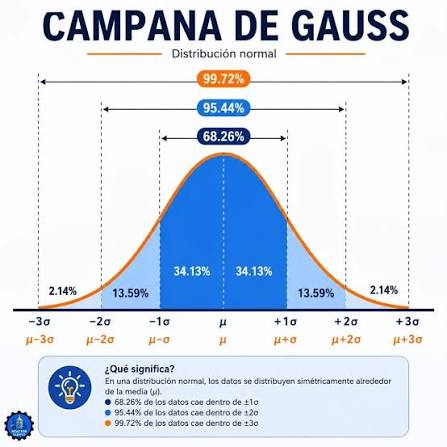

Las dos medias son iguales (70), pero el grupo B está mucho más disperso. La desviación estándar lo deja en evidencia.

**Regla útil:** cuando los datos se reparten de forma "normal" (en forma de campana), alrededor del **68 %** de los datos cae entre `media - 1 desviación` y `media + 1 desviación`, y cerca del **95 %** entre `media - 2` y `media + 2`.

Hay otra medida parecida: la **varianza** (`var()`), que es la desviación elevada al cuadrado. Se usa en cálculos más avanzados, pero para interpretar es más cómoda la desviación porque está en las unidades originales.

### Detalles a tener en cuenta en este `describe()`

- Mira el **count** de las columnas: es menor a 344. Confirma los datos faltantes.
- La columna `year` aparece como si fuera una medida, pero es solo el año. Calcularle la media no tiene sentido: ignórala en la interpretación.

### Las columnas de texto

In [53]:
pinguinos.describe(exclude="number")     # resumen de las columnas que NO son numéricas

,species,island,sex
count,344,344,333
unique,3,3,2
top,Adelie,Biscoe,male
freq,152,168,168


In [54]:
pinguinos["species"].value_counts()      # cuántos pingüinos hay de cada especie

,count
species,
Adelie,152
Gentoo,124
Chinstrap,68


In [55]:
pinguinos["island"].value_counts()

,count
island,
Biscoe,168
Dream,124
Torgersen,52


In [56]:
pinguinos["species"].unique()            # lista de valores distintos

array(['Adelie', 'Gentoo', 'Chinstrap'], dtype=object)

Con esto ya sabemos: cuántos datos hay, de qué tipo son, que existen tres especies y tres islas, y que **faltan datos**. Es momento de pensar cómo organizar el trabajo de limpieza.

---
# Parte 5. Arquitectura Medallón

## ¿Qué es?

La **Arquitectura Medallón** (*Medallion Architecture*) es una forma de organizar los datos en **tres capas** a medida que pasan de "crudos" a "listos para usar". Nace de la ingeniería de datos moderna (la popularizó Databricks) y hoy se usa en muchas empresas.

**Idea central: nunca trabajes directamente sobre tus datos originales.** Se conserva una copia intacta y cada etapa de limpieza produce una versión nueva.

**Analogía de la cocina:** el restaurante recibe los ingredientes tal como llegan del mercado (con tierra y sin pelar), luego los lava, pela y corta, y al final prepara platos listos para servir al cliente. Si el plato sale mal, siempre se puede volver a empezar desde los ingredientes originales.

```
  BRONCE                    PLATA                      ORO
  Datos crudos      →       Datos limpios      →       Datos para decidir
  (como llegaron)           (ordenados y validados)    (resúmenes, tablas y gráficas)
```

### 🥉 Capa Bronce: datos crudos
- Son los datos **exactamente como llegaron** de la fuente: un CSV, un JSON, un volcado de base de datos.
- Pueden tener faltantes, textos inconsistentes, duplicados o columnas mal nombradas.
- **No se modifican**. Sirven como respaldo y como punto de partida.
- *En esta clase:* el DataFrame recién cargado con `read_csv()`.

### 🥈 Capa Plata: datos limpios
- Es la versión **depurada**: sin faltantes problemáticos, con nombres claros, tipos correctos y textos consistentes.
- Aquí aplicamos el trabajo de la Unidad 37.
- *En esta clase:* el DataFrame después de tratar nulos, unificar textos y renombrar columnas.

### 🥇 Capa Oro: datos listos para el negocio
- Son tablas **resumidas** y listas para que alguien tome decisiones: promedios por grupo, conteos, reportes, gráficas, entradas para un modelo.
- *En esta clase:* las tablas de promedios y las tres gráficas finales.

## ¿Por qué conviene trabajar así?

- **Trazabilidad:** sabes de dónde salió cada número.
- **Seguridad:** si te equivocas al limpiar, el original sigue ahí.
- **Reutilización:** una misma capa Plata puede alimentar muchos reportes distintos.
- **Orden:** cada capa tiene un propósito claro.

> Empresas grandes lo hacen con herramientas como Databricks y Delta Lake. El concepto es el mismo que aplicaremos con Pandas y tres carpetas.

### Armando las tres capas en nuestro proyecto

In [57]:
# Una carpeta por capa
os.makedirs("datos/bronce", exist_ok=True)
os.makedirs("datos/plata", exist_ok=True)
os.makedirs("datos/oro", exist_ok=True)

os.listdir("datos")

['bronce', 'plata', 'oro']

In [58]:
# BRONCE: guardamos los datos tal como llegaron, sin tocarlos
bronce = pinguinos.copy()
bronce.to_csv("datos/bronce/pinguinos_bronce.csv", index=False)

os.listdir("datos/bronce")

['pinguinos_bronce.csv']

Usamos `.copy()` para tener una copia **independiente**: lo que hagamos después con otras variables no modificará `bronce`.

---
# Parte 6. De Bronce a Plata: tratamiento de los datos (Unidad 37)

## 6.1 Datos ordenados: *Tidy Data*

Hadley Wickham propuso que una tabla está **ordenada** (*tidy*) cuando cumple tres reglas:

1. **Cada variable tiene su propia columna.**
2. **Cada observación tiene su propia fila.**
3. **Cada valor tiene su propia celda.**

Una tabla ordenada es mucho más fácil de filtrar, agrupar y graficar. El caso más típico de tabla **desordenada** es cuando **los encabezados son valores** en lugar de variables:

In [59]:
# DESORDENADA: "Enero" y "Febrero" son valores del mes, pero están como columnas
desordenada = pd.DataFrame({
    "estudiante": ["Ana", "Luis"],
    "Enero":   [85, 70],
    "Febrero": [90, 75],
})
desordenada

,estudiante,Enero,Febrero
0,Ana,85,90
1,Luis,70,75


In [60]:
# ORDENADA: una columna "mes", una columna "nota", una fila por observación
ordenada = pd.DataFrame({
    "estudiante": ["Ana", "Ana", "Luis", "Luis"],
    "mes":        ["Enero", "Febrero", "Enero", "Febrero"],
    "nota":       [85, 90, 70, 75],
})
ordenada

,estudiante,mes,nota
0,Ana,Enero,85
1,Ana,Febrero,90
2,Luis,Enero,70
3,Luis,Febrero,75


Otros síntomas de datos desordenados: dos variables metidas en una misma columna (por ejemplo `"Macho-Adelie"`), unidades dentro del dato (`"3750g"`) o una variable repartida en varias columnas.

**¿Y nuestros pingüinos?** Cada fila es un pingüino, cada columna es una variable y cada celda tiene un solo valor. **Ya están ordenados**, así que nuestro trabajo se centra en los **datos faltantes** y en la **consistencia**.

## 6.2 Valores faltantes

### Detectarlos

In [61]:
bronce.isnull().sum()          # cuántos NaN hay por columna

,0
species,0
island,0
bill_length_mm,2
bill_depth_mm,2
flipper_length_mm,2
body_mass_g,2
sex,11
year,0


### ¿En qué filas están?

`isnull()` devuelve una tabla de verdadero/falso. Con `.any(axis=1)` preguntamos, **fila por fila**, "¿hay algún faltante en esta fila?". Usamos eso como filtro:

In [62]:
bronce[bronce.isnull().any(axis=1)]

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
8,Adelie,Torgersen,34.1,18.1,193.0,3475.0,NaN,2007
9,Adelie,Torgersen,42.0,20.2,190.0,4250.0,NaN,2007
10,Adelie,Torgersen,37.8,17.1,186.0,3300.0,NaN,2007
11,Adelie,Torgersen,37.8,17.3,180.0,3700.0,NaN,2007
47,Adelie,Dream,37.5,18.9,179.0,2975.0,NaN,2007
178,Gentoo,Biscoe,44.5,14.3,216.0,4100.0,NaN,2007
218,Gentoo,Biscoe,46.2,14.4,214.0,4650.0,NaN,2008
256,Gentoo,Biscoe,47.3,13.8,216.0,4725.0,NaN,2009
268,Gentoo,Biscoe,44.5,15.7,217.0,4875.0,NaN,2009


Hay dos tipos de casos:

- Filas donde **faltan todas las medidas** (pico, aleta y peso): una fila así no sirve para el análisis.
- Filas donde **solo falta el sexo**: el resto de la información sí es útil.

Tratarlos distinto es justo lo que haremos.

### Opciones para tratar faltantes

1. **Eliminar** (`dropna`): cuando el dato faltante hace inútil la fila o es muy poco.
2. **Reemplazar / imputar** (`fillna`): cuando queremos conservar la fila y tiene sentido rellenar el hueco.

Practiquemos primero con una tabla pequeña. Es una estación meteorológica con datos que no se registraron:

In [63]:
import numpy as np

clima = pd.DataFrame({
    "dia":         [np.nan, 2, 3, 4, 5, 6],
    "temperatura": [31.1, 31.0, np.nan, 33.0, np.nan, 35.0],
    "lluvia_mm":   [np.nan , np.nan, np.nan, np.nan, np.nan, np.nan],
    "ciudad":      [None, "Panamá", "Panamá", None, "Panamá", "Panamá"],
})
clima

,dia,temperatura,lluvia_mm,ciudad
0,NaN,31.1,NaN,None
1,2.0,31.0,NaN,Panamá
2,3.0,NaN,NaN,Panamá
3,4.0,33.0,NaN,None
4,5.0,NaN,NaN,Panamá
5,6.0,35.0,NaN,Panamá


### Eliminar con `dropna()`

In [64]:
clima.dropna()                      # elimina TODA fila que tenga algún NaN

,dia,temperatura,lluvia_mm,ciudad


In [65]:
clima.dropna(axis=1)                # axis=1: elimina COLUMNAS que tengan algún NaN

""
0
1
2
3
4
5


In [66]:
clima.dropna(how="all")             # solo elimina filas donde TODO es NaN (aquí ninguna)

,dia,temperatura,lluvia_mm,ciudad
0,NaN,31.1,NaN,None
1,2.0,31.0,NaN,Panamá
2,3.0,NaN,NaN,Panamá
3,4.0,33.0,NaN,None
4,5.0,NaN,NaN,Panamá
5,6.0,35.0,NaN,Panamá


In [67]:
clima.dropna(subset=["temperatura"])   # mira solo la columna indicada: elimina filas sin temperatura

,dia,temperatura,lluvia_mm,ciudad
0,NaN,31.1,NaN,None
1,2.0,31.0,NaN,Panamá
3,4.0,33.0,NaN,None
5,6.0,35.0,NaN,Panamá


- `axis`: `0` elimina filas, `1` elimina columnas.
- `how="any"` (por defecto): basta con un NaN. `how="all"`: deben ser NaN todos.
- `subset=[...]`: limita la revisión a ciertas columnas.

### Rellenar con `fillna()`

**Con un número fijo** (¡cuidado, a veces es mala idea!):

In [68]:
clima["temperatura"].fillna(0)      # una temperatura de 0 °C inventada distorsionaría todo

,temperatura
0,31.1
1,31.0
2,0.0
3,33.0
4,0.0
5,35.0


**Con la media** (para datos numéricos donde un valor "típico" es razonable):

In [69]:
clima["temperatura"].fillna(clima["temperatura"].mean())

,temperatura
0,31.100
1,31.000
2,32.525
3,33.000
4,32.525
5,35.000


**Con la moda** (para texto o categorías: el valor más repetido). `mode()` devuelve una Series, por eso usamos `[0]` para tomar el primero:

In [70]:
clima["ciudad"].fillna(clima["ciudad"].mode()[0])

,ciudad
0,Panamá
1,Panamá
2,Panamá
3,Panamá
4,Panamá
5,Panamá


**Con el vecino cercano** (*forward fill* y *backward fill*). Es útil cuando los datos son **continuos o ordenados en el tiempo**, como la temperatura de un día a otro:

In [71]:
clima["temperatura"].ffill()        # copia el valor anterior hacia adelante

,temperatura
0,31.1
1,31.0
2,31.0
3,33.0
4,33.0
5,35.0


In [72]:
clima["temperatura"].bfill()        # copia el siguiente valor hacia atrás

,temperatura
0,31.1
1,31.0
2,33.0
3,33.0
4,35.0
5,35.0


**¿Cuál elegir?** Depende del dato. Preguntas útiles:

- ¿Rellenar inventa información que podría ser falsa? (No inventes un sexo, un diagnóstico o una nota.)
- ¿Hay muchos faltantes? Si a una columna le falta casi todo (como `lluvia_mm`), imputar es poco fiable; quizá conviene eliminarla.
- ¿Los datos tienen orden temporal? Entonces `ffill` / `bfill` suelen tener sentido.

## 6.3 Aplicándolo a los pingüinos (Bronce → Plata)

Partimos de una copia del Bronce:

In [73]:
plata = bronce.copy()
plata.shape

(344, 8)

In [74]:
bronce.isnull().sum()

,0
species,0
island,0
bill_length_mm,2
bill_depth_mm,2
flipper_length_mm,2
body_mass_g,2
sex,11
year,0


**Decisión 1:** las filas donde faltan **todas las medidas** no sirven. Las eliminamos con `dropna`, usando `subset` (solo miramos las 4 columnas de medidas) y `how="all"` (solo si **todas** están vacías).

In [75]:
medidas_originales = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]

plata = plata.dropna(subset=medidas_originales, how="all")
plata.shape

(342, 8)

In [76]:
plata.isnull().sum()

,0
species,0
island,0
bill_length_mm,0
bill_depth_mm,0
flipper_length_mm,0
body_mass_g,0
sex,9
year,0


Ya no faltan medidas. Solo queda el **sexo** con huecos.

**Decisión 2:** para el sexo **no usaremos la moda ni inventaremos un valor**: sería afirmar algo que no sabemos. Marcaremos esos casos como `"desconocido"`.

Antes, un paso de **consistencia de texto**. Los textos pueden venir con mayúsculas distintas (`Male`, `male`, `MALE`), y Pandas los consideraría valores diferentes. Los pasamos a minúsculas y de paso los traducimos:

In [77]:
plata["sex"] = plata["sex"].str.lower()          # unifica mayúsculas/minúsculas
plata["sex"].value_counts()

,count
sex,
male,168
female,165


In [78]:
plata["sex"] = plata["sex"].replace({"male": "macho", "female": "hembra"})
plata["sex"] = plata["sex"].fillna("desconocido")
plata["sex"].value_counts()

,count
sex,
macho,168
hembra,165
desconocido,9


In [79]:
plata.isnull().sum()           # comprobamos: debe quedar todo en cero

,0
species,0
island,0
bill_length_mm,0
bill_depth_mm,0
flipper_length_mm,0
body_mass_g,0
sex,0
year,0


## 6.4 Duplicados

Otra revisión clásica: ¿hay filas repetidas?

In [80]:
plata.duplicated().sum()       # cuántas filas están repetidas

np.int64(0)

In [81]:
plata = plata.drop_duplicates()    # elimina duplicados (si no hay, no cambia nada)
plata.shape

(342, 8)

## 6.5 Nombres claros: renombrar columnas

En la capa Plata las columnas deben ser **claras y consistentes**. Las pasamos al español:

In [82]:
plata = plata.rename(columns={
    "species": "especie",
    "island": "isla",
    "bill_length_mm": "largo_pico_mm",
    "bill_depth_mm": "profundidad_pico_mm",
    "flipper_length_mm": "largo_aleta_mm",
    "body_mass_g": "peso_g",
    "sex": "sexo",
    "year": "anio",
})
plata.head()

,especie,isla,largo_pico_mm,profundidad_pico_mm,largo_aleta_mm,peso_g,sexo,anio
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,macho,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,hembra,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,hembra,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,hembra,2007
5,Adelie,Torgersen,39.3,20.6,190.0,3650.0,macho,2007


In [83]:
plata.info()

<class 'pandas.core.frame.DataFrame'>
Index: 342 entries, 0 to 343
Data columns (total 8 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   especie              342 non-null    object 
 1   isla                 342 non-null    object 
 2   largo_pico_mm        342 non-null    float64
 3   profundidad_pico_mm  342 non-null    float64
 4   largo_aleta_mm       342 non-null    float64
 5   peso_g               342 non-null    float64
 6   sexo                 342 non-null    object 
 7   anio                 342 non-null    int64  
dtypes: float64(4), int64(1), object(3)
memory usage: 24.0+ KB


## 6.6 Estadística descriptiva con datos limpios

In [84]:
plata.describe().round(1)

,largo_pico_mm,profundidad_pico_mm,largo_aleta_mm,peso_g,anio
count,342.0,342.0,342.0,342.0,342.0
mean,43.9,17.2,200.9,4201.8,2008.0
std,5.5,2.0,14.1,802.0,0.8
min,32.1,13.1,172.0,2700.0,2007.0
25%,39.2,15.6,190.0,3550.0,2007.0
50%,44.4,17.3,197.0,4050.0,2008.0
75%,48.5,18.7,213.0,4750.0,2009.0
max,59.6,21.5,231.0,6300.0,2009.0


Compara con el `describe()` de antes: ahora el `count` es igual en todas las columnas.

### Coeficiente de variación (CV)

Si quiero saber **cuál variable es más dispersa**, no puedo comparar directamente las desviaciones: el peso se mide en **gramos** (miles) y el pico en **milímetros** (decenas). Una desviación de 800 g y una de 3 mm no son comparables.

El **coeficiente de variación** resuelve esto: divide la desviación entre la media y la expresa en porcentaje. Así **no tiene unidades** y permite comparar variables de escalas distintas.

`CV = desviación estándar / media × 100`

In [85]:
medidas = ["largo_pico_mm", "profundidad_pico_mm", "largo_aleta_mm", "peso_g"]

media = plata[medidas].mean()
desviacion = plata[medidas].std()

media.round(1)

,0
largo_pico_mm,43.9
profundidad_pico_mm,17.2
largo_aleta_mm,200.9
peso_g,4201.8


In [86]:
desviacion.round(1)

,0
largo_pico_mm,5.5
profundidad_pico_mm,2.0
largo_aleta_mm,14.1
peso_g,802.0


In [87]:
cv = desviacion / media * 100
cv.round(1)

,0
largo_pico_mm,12.4
profundidad_pico_mm,11.5
largo_aleta_mm,7.0
peso_g,19.1


Mira cuál variable tiene el CV más alto: es la que **varía más en términos relativos** entre un pingüino y otro.

## 6.7 Valores atípicos (outliers) con el diagrama de caja

Un **valor atípico** es un dato muy alejado del resto. Puede ser un **error** (alguien escribió 40000 en vez de 4000) o un **dato real pero extremo**.

El **diagrama de caja** (*box plot*) los muestra visualmente, y usa los cuartiles que ya conocemos:

- La **caja** va de **Q1 (25 %) a Q3 (75 %)**: contiene el 50 % central de los datos.
- La **línea dentro de la caja** es la **mediana**.
- Los **bigotes** se extienden hasta los datos que están dentro de **1.5 × IQR** desde la caja.
- Los **puntos sueltos** fuera de los bigotes son los **atípicos**.

Primero calculamos los límites a mano:

In [88]:
q1 = plata["peso_g"].quantile(0.25)
q3 = plata["peso_g"].quantile(0.75)
iqr = q3 - q1

limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

print("Q1:", q1, "| Q3:", q3, "| IQR:", iqr)
print("Límites:", limite_inferior, "a", limite_superior)

Q1: 3550.0 | Q3: 4750.0 | IQR: 1200.0
Límites: 1750.0 a 6550.0


In [89]:
# Filas cuyo peso queda fuera de los límites
atipicos = plata[(plata["peso_g"] < limite_inferior) | (plata["peso_g"] > limite_superior)]
len(atipicos)

0

Y ahora el diagrama de caja del peso:

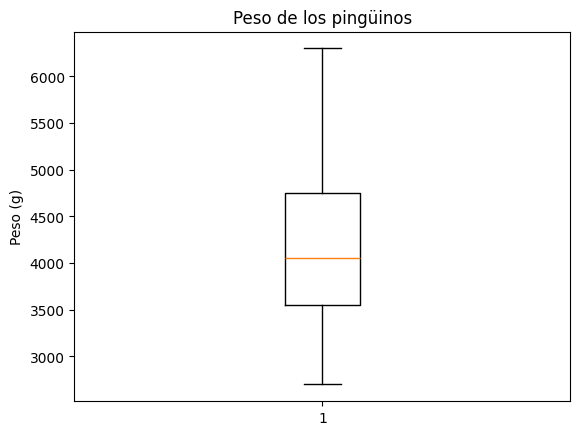

In [90]:
plt.boxplot(plata["peso_g"])
plt.title("Peso de los pingüinos")
plt.ylabel("Peso (g)")
plt.show()

Los pingüinos son de **tres especies muy distintas**, así que conviene mirar el peso **por especie**. Separamos la tabla en tres:

In [91]:
adelie = plata[plata["especie"] == "Adelie"]
chinstrap = plata[plata["especie"] == "Chinstrap"]
gentoo = plata[plata["especie"] == "Gentoo"]

len(adelie), len(chinstrap), len(gentoo)

(151, 68, 123)

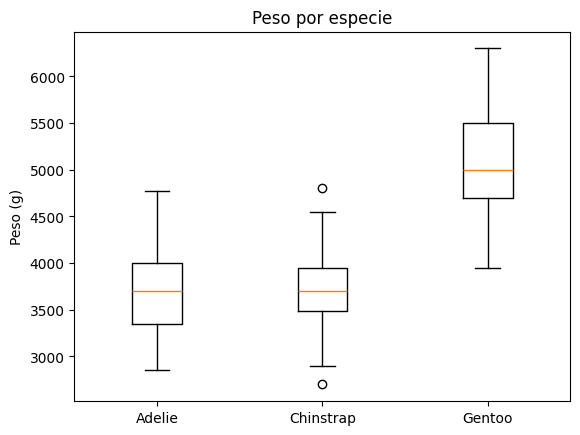

In [92]:
plt.boxplot([adelie["peso_g"], chinstrap["peso_g"], gentoo["peso_g"]])
plt.xticks([1, 2, 3], ["Adelie", "Chinstrap", "Gentoo"])
plt.title("Peso por especie")
plt.ylabel("Peso (g)")
plt.show()

**¿Qué hacemos con un atípico?** No se borra automáticamente. Primero se pregunta: ¿es un error de captura (corregir o eliminar) o un valor real pero extremo (conservar)? Una medida rara **dentro de una especie** puede ser perfectamente natural.

## 6.8 Correlación entre variables

La **correlación** mide qué tan relacionadas están dos variables. Va de **-1 a +1**:

- Cerca de **+1**: cuando una sube, la otra también.
- Cerca de **0**: no hay relación lineal.
- Cerca de **-1**: cuando una sube, la otra baja.

In [93]:
plata[medidas].corr().round(2)

,largo_pico_mm,profundidad_pico_mm,largo_aleta_mm,peso_g
largo_pico_mm,1.00,-0.24,0.66,0.60
profundidad_pico_mm,-0.24,1.00,-0.58,-0.47
largo_aleta_mm,0.66,-0.58,1.00,0.87
peso_g,0.60,-0.47,0.87,1.00


Busca la pareja con la correlación más alta. Y una pregunta para pensar: una correlación calculada con **las tres especies mezcladas** puede decir cosas distintas a la de **cada especie por separado**. Lo exploraremos con la gráfica de dispersión.

> Recuerda: correlación **no** es causalidad. Que dos variables vayan juntas no significa que una cause la otra.

### Guardamos la capa Plata

In [94]:
plata.to_csv("datos/plata/pinguinos_plata.csv", index=False)
os.listdir("datos/plata")

['pinguinos_plata.csv']

---
# Parte 7. De Plata a Oro: generar información

La capa Oro son **tablas resumen** que responden preguntas concretas. Usaremos `groupby()`, que funciona así: **separa la tabla en grupos** (por ejemplo, uno por especie) y **calcula algo para cada grupo**.

**Pregunta 1: ¿cuántos pingüinos hay de cada especie?**

In [95]:
conteo = plata["especie"].value_counts()
conteo

,count
especie,
Adelie,151
Gentoo,123
Chinstrap,68


**Pregunta 2: ¿cómo son las medidas promedio de cada especie?**

In [96]:
promedios = plata.groupby("especie")[medidas].mean().round(1)
promedios

,largo_pico_mm,profundidad_pico_mm,largo_aleta_mm,peso_g
especie,,,,
Adelie,38.8,18.3,190.0,3700.7
Chinstrap,48.8,18.4,195.8,3733.1
Gentoo,47.5,15.0,217.2,5076.0


**Pregunta 3: ¿cómo se reparte el peso dentro de cada especie?** `describe()` también funciona por grupo, y nos devuelve los percentiles y la desviación de cada una:

In [97]:
peso_detalle = plata.groupby("especie")["peso_g"].describe().round(1)
peso_detalle

,count,mean,std,min,25%,50%,75%,max
especie,,,,,,,,
Adelie,151.0,3700.7,458.6,2850.0,3350.0,3700.0,4000.0,4775.0
Chinstrap,68.0,3733.1,384.3,2700.0,3487.5,3700.0,3950.0,4800.0
Gentoo,123.0,5076.0,504.1,3950.0,4700.0,5000.0,5500.0,6300.0


**Pregunta 4: ¿cómo cambió el peso promedio año a año en cada especie?** Usamos `pivot_table`, que funciona como una **tabla dinámica de Excel**: filas = año, columnas = especie, valores = promedio del peso.

In [98]:
peso_anio = plata.pivot_table(index="anio", columns="especie", values="peso_g").round(1)
peso_anio

especie,Adelie,Chinstrap,Gentoo
anio,,,
2007,3696.4,3694.2,5070.6
2008,3742.0,3800.0,5019.6
2009,3664.9,3725.0,5140.7


**Pregunta 5: ¿cuántos machos, hembras y desconocidos hay?**

In [99]:
plata["sexo"].value_counts()

,count
sexo,
macho,168
hembra,165
desconocido,9


### Guardamos la capa Oro

Exportamos las tablas resumen a Excel, listas para compartir con quien trabaje en esa herramienta.

In [100]:
promedios.to_excel("datos/oro/promedios_por_especie.xlsx")
peso_anio.to_excel("datos/oro/peso_por_anio.xlsx")

os.listdir("datos/oro")

['promedios_por_especie.xlsx', 'peso_por_anio.xlsx']

---
# Parte 8. Tres gráficas con Matplotlib

Ya tenemos información. Ahora la comunicamos con tres gráficas simples. Una buena gráfica siempre lleva **título, nombres en los ejes** y, si hay varias series, **leyenda**.

## Gráfica 1: barras, para comparar categorías

¿Qué especie pesa más en promedio?

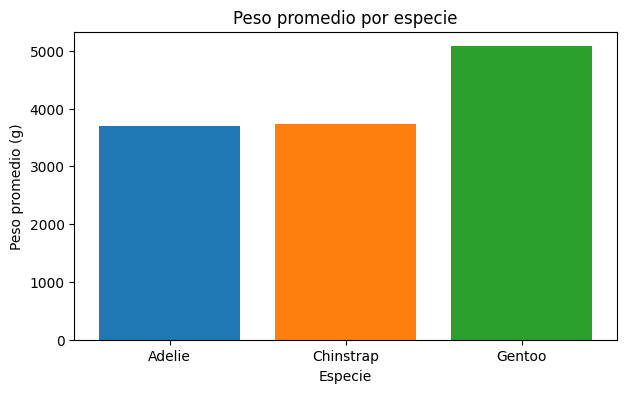

In [101]:
plt.figure(figsize=(7, 4))
plt.bar(promedios.index, promedios["peso_g"], color=["tab:blue", "tab:orange", "tab:green"])
plt.title("Peso promedio por especie")
plt.xlabel("Especie")
plt.ylabel("Peso promedio (g)")
plt.savefig("datos/oro/grafica_barras.png")
plt.show()

## Gráfica 2: dispersión, para ver la relación entre dos variables

¿Los pingüinos con aletas más largas pesan más? Cada punto es un pingüino y los coloreamos por especie. Hacemos un `scatter` por cada especie (las tres tablas que separamos antes).

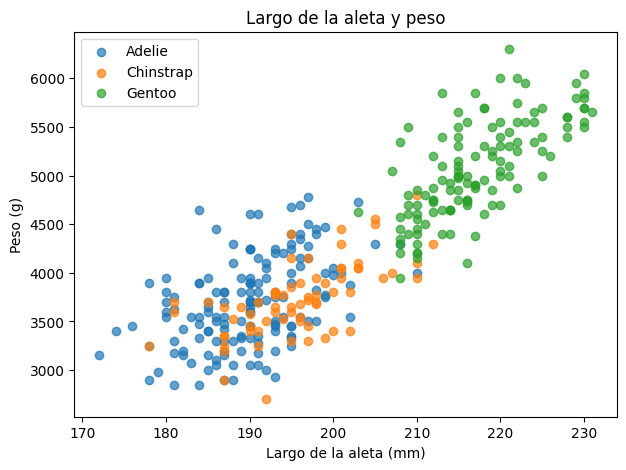

In [102]:
plt.figure(figsize=(7, 5))
plt.scatter(adelie["largo_aleta_mm"], adelie["peso_g"], color="tab:blue", alpha=0.7, label="Adelie")
plt.scatter(chinstrap["largo_aleta_mm"], chinstrap["peso_g"], color="tab:orange", alpha=0.7, label="Chinstrap")
plt.scatter(gentoo["largo_aleta_mm"], gentoo["peso_g"], color="tab:green", alpha=0.7, label="Gentoo")

plt.title("Largo de la aleta y peso")
plt.xlabel("Largo de la aleta (mm)")
plt.ylabel("Peso (g)")
plt.legend()
plt.savefig("datos/oro/grafica_dispersion.png")
plt.show()

Observa cómo se forman **grupos**: cada especie ocupa una zona distinta. Eso explica por qué mezclar las especies puede cambiar las correlaciones.

## Gráfica 3: líneas, para ver la evolución en el tiempo

Usamos la tabla dinámica `peso_anio`: una línea por especie.

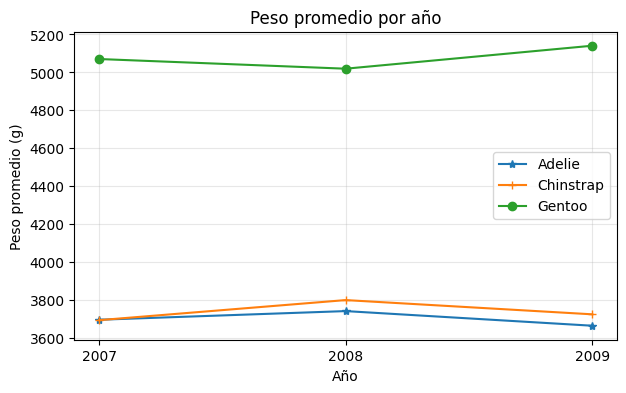

In [103]:
plt.figure(figsize=(7, 4))
plt.plot(peso_anio.index, peso_anio["Adelie"], marker="*", label="Adelie")
plt.plot(peso_anio.index, peso_anio["Chinstrap"], marker="+", label="Chinstrap")
plt.plot(peso_anio.index, peso_anio["Gentoo"], marker="o", label="Gentoo")

plt.title("Peso promedio por año")
plt.xlabel("Año")
plt.ylabel("Peso promedio (g)")
plt.xticks(peso_anio.index)
plt.legend()
plt.grid(alpha=0.3)
plt.savefig("datos/oro/grafica_lineas.png")
plt.show()

> Como solo hay pocos años, cada línea tiene pocos puntos. Con más años la gráfica de líneas muestra mejor las tendencias.